### ORIENTATION ANALYSIS FOR STABILITY TESTS 

Goals: 
1. plot RMSD for hydrogen and oxygen separately 
2. Look at orientation changes of hydrogen in stability tests 

In [1]:
import signac 
import freud 
import hoomd 
import gsd.hoomd
import os

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["axes.titlepad"] = 20
import rowan  # for quaternion math, see rowan.readthedocs.io for more information.
from mpl_toolkits.mplot3d import Axes3D

import hoomd 
import ase.io
from ase.formula import Formula
import json 
import coxeter 


In [2]:
def get_shape_info(input_dir, N_scaling, types, crystal_name, stoich):
    """
    Inputs: 
    N_scaling = replication size of simulation box 
    types = array of strings of atoms types (i.e. ["O", "H"]), order doesn't matter
    cif = cif file for crystal you're assembling 

    Outputs: 
    atoms = ase "Atom" object 
    uc_atom_counts = dictionary of atom type and number of atom type (i.e {'O': 36, 'H': 72}) 
    sim_type_counts = list of number of particles of each type  
    type_shapes = "type_shape" dictionary for hoomd: type, rounding radius, vertices from json file 
    typeid = list assigning type to every particle (in order of "sim_type_counts") in box 
    shape_json_dicts = list of dictionaries from crystal2shape json files (one for each type) 
    spacing = spacing between lattice points, 2.2 times the larger minimal bounding radius of the shapes in the uc 
    shape_volume = total volume taken by all the particles in the simulation 
    """
    cif = input_dir + f"{crystal_name}.cif"
    atoms = ase.io.read(cif)
    uc_atom_counts = Formula(str(atoms.symbols)).count()
    sim_type_counts = []
    type_shapes = [] 
    typeid = []
    shape_json_dicts = []
    radius = []
    shape_volume = 0
    for i, type in enumerate(types): 
        shape_file = input_dir + f"shape_{crystal_name}_{type}_unit_volume_principal_frame.json"
        # determine type of each particle in simulation from replicas AND stoich specification - hard codes "O" as reference
        sim_type_counts.append(uc_atom_counts[types[0]] * stoich[type] * N_scaling ** 3) # N_scaling is "replicas" which could be made, so cubed for 3D  
        typeid = typeid + ([i] * sim_type_counts[i])
        with open(shape_file) as file: 
            shape_json_dicts.append(json.load(file))
            type_shapes.append(dict(type="ConvexPolyhedron", 
                                    rounding_radius = 0,
                                    vertices = shape_json_dicts[i]["8_vertices"]))
            poly=coxeter.shapes.ConvexPolyhedron(shape_json_dicts[i]["8_vertices"])
            radius.append(poly.minimal_bounding_sphere.radius)
            shape_volume += shape_json_dicts[i]["4_Volume"] * sim_type_counts[i]
    
    spacing = 2.2 * max(radius)

    return sim_type_counts, type_shapes, typeid, shape_json_dicts, spacing, shape_volume



In [3]:
# initialize project 

project = signac.init_project("/home/clarivi/projects/IceCrystal_Project/data/data/")

jobs = [job.id for job in project.find_jobs({"crystal_name":"141_H2O_0", "compression": False})]
print(jobs)

['c51995dcb0b975c10e58c74151f457bb', '91e50c511d9f90bd01496dce072909f0', '2dbdb2278e3bd87571c5741e04847fbf']


### Relative Orientation Analysis: 

Using freud relative orientation to understand how the hydrogen particle orientation is changing over the course of the simulation

BRAINSTORMING: 
- I need to find the equivalent orientations of my shapes in order to use this algorithm -- how to find the symmetry 
- Q: does the point set used to generate the shape necessarily have the same symmetry as the shape itself?  

In [4]:
#for every stability test job 
for job in project.find_jobs({"compression": False}):
    if os.path.isfile(job.fn("trajectory.gsd")):
        data = gsd.hoomd.open(job.fn("trajectory.gsd"), 'r')
    else: 
        data = gsd.hoomd.open(job.fn("trajectory_temp.gsd"), 'r')

    ## Find equivalent orientations for shape: 
    
    ref_box, ref_points = data[0].configuration.box, data[0].particles.position
    ref_orientations = data[0].particles.orientation

    avg_angular_sep = np.zeros(len(data))

    for frame in range(len(data)):
        box, points = data[frame].configuration.box, data[frame].particles.position
        orientations = data[frame].particles.orientation


IndexError: 

### Mean squared relative displacement 

- identify 2 nearest oxygen neighbors of each hydrogen 
- calculate mean square displacement of all 3 particles, take the difference? 
- might actually be easier to do as pairs? 

calculate per particle mean squared displacement, then take difference between that for pairs of oxygen, hydrogen 


In [4]:
# find all oxygen nearest neighbors of hydrogen particles: 2 nearest neighbors of type oxygen using freud 

for job in project.find_jobs({"compression": False}):
    print(job.id)
    if os.path.isfile(job.fn("trajectory.gsd")):
        data = gsd.hoomd.open(job.fn("trajectory.gsd"), 'r')
    else: 
        data = gsd.hoomd.open(job.fn("trajectory_temp.gsd"), 'r')

    _, _, _, shapes, spacing, _ = get_shape_info(job.sp.inputfile, 
                                                            job.sp.replicas, 
                                                            job.sp.atoms, 
                                                            job.sp.crystal_name,
                                                            job.sp.stoich)
    diameter = spacing / 2.2 

    plot_points = 10
    oxygen_neighbors = np.zeros(plot_points)

    for frame in range(plot_points):
        data_frame = int(frame * len(data)/plot_points)

        #points are only oxygen atoms 
        point_ids = np.where(data[data_frame].particles.typeid)
        box, points = data[data_frame].configuration.box, data[data_frame].particles.position[point_ids]

        aq = freud.locality.AABBQuery(box, points)

        #query points are only hydrogen atoms 
        query_ids = np.where(data[data_frame].particles.typeid == 1)

        query_points = data[data_frame].particles.position[query_ids]

        distances = []

        #find 2 nearest neighbors - in perfect crystal, these should both be oxygen particles
        query_result = aq.query(query_points, dict(num_neighbors=4, exclude_ii=True))

        nlist = query_result.toNeighborList()

        # find average number of hydrogen nearest neighbors which are oxygen: 
        oxygen_neighbor_list = np.zeros(len(query_points))
        hydrogen_neighbor_list = np.zeros(len(query_points))

        
        HO_pair_list = [[i, j] for i, j in nlist if [data[data_frame].particles.typeid[i], data[data_frame].particles.typeid[j]] == [1, 0]]

        r_max = 5

        ld = freud.density.LocalDensity(r_max, diameter)

        ld.compute(system=(box, points), query_points=query_points,
           neighbors=nlist)

        ld_oxygen = ld.density
        print(ld_oxygen)
        # oxygen_neighbor_list = [ for i in range(len(HO_pair_list))]
        # for i, j in HO_pair_list:
        #     oxygen_neighbor_list[i] += 1 
        

        #oxygen_neighbors[frame] = np.average(oxygen_neighbor_list)
        oxygen_neighbors[frame] = np.average(ld_oxygen)


    plt.plot(oxygen_neighbors)
    plt.title(f"{job.sp.crystal_name}, with {job.sp.runtime} steps")
    plt.show()

  
        
        

3787a6d7cedd2704d2fd55a25bc95b10
[0.00763944 0.00763944 0.00763944 ... 0.00763944 0.00763944 0.00763944]
[0.00763944 0.00763944 0.00763944 ... 0.00763944 0.00763944 0.00763944]


KeyboardInterrupt: 

In [4]:
def image_retrieval(file, outfile):
    """
    Inputs: 
    file - input gsd file 
    savefile - output npy file 

    Outputs: 
    npy file, saving array of images in shape (timesteps, N, 3) 
    """
    #open file without images 
    traj = gsd.hoomd.open(file)
    original_image = traj[0].particles.image 

    ### constants ###
    N_particles = traj[0].particles.N
    N_steps = len(traj)

    #create array of correct size for all images (timesteps, N, 3)
    image_array = np.zeros((N_steps, N_particles, 3))

    #append original images for frame zero 
    #image_array[0, :, :] = original_image 

    #create array to compare position differences to: 

    L_halves = np.array([traj[0].configuration.box[0:3]] * N_particles) / 2

    for f, frame in enumerate(traj[1:]):
        # i will start from 0 but updating images starts at n = 1
        i = f + 1
        ### step 1 ### 
        prev_frame = traj[i - 1]
        displacement = frame.particles.position - prev_frame.particles.position

        ### step 2 ### 
        #check is Li/2 is greater than absolute value of displacement of each particle 
        image_mag = np.less(L_halves, np.abs(displacement)).astype(int)

        ### step 3 ### 
        # sets sign for image based on sign of displacement 
        image_sign = np.greater(0, displacement).astype(int)

        #if displacement is negative (less than zero), image is positive
        image_sign[image_sign == 1] = 1

        # if displacement is positive (greater than 0), image is negative
        image_sign[image_sign == 0] = -1

        ### step 4 ### 
        image = image_mag * image_sign 

        image_array[i, :, :] = image_array[f, :, :] + image 

    np.save(outfile, image_array)
    return image_array

def com(unwrapped_positions, masses, N):
    position_scaled_masses = [unwrapped_positions[:, i, :] * masses[i] for i in range(N)]
    print(f"size of position scaled masses: {np.shape(position_scaled_masses)}")
    #print("position scaled masses ", position_scaled_masses)
    
    sum_psm = np.sum(position_scaled_masses, axis=0)
    print("size of final position of masses ", np.shape(sum_psm))

    total_mass = np.sum(masses)

    center_of_mass = sum_psm/total_mass

    return center_of_mass

In [ ]:
### Pair correlation functions 

for job in project.find_jobs({"compression": False, "crystal_name": "141_H2O_0"}):
    if job.id != "d59772ff5157b86e4e02f4cab5f04d52":
        if os.path.isfile(job.fn("trajectory.gsd")):
                    data = gsd.hoomd.open(job.fn("trajectory.gsd"), 'r')
                    image_retrieval(job.fn("trajectory.gsd"), job.fn("images.npy"))
        else: 
            data = gsd.hoomd.open(job.fn("trajectory_temp.gsd"), 'r')
            print(data)
            if data == None: 
                print("no data")    
                break
            image_retrieval(job.fn("trajectory_temp.gsd"), job.fn("images.npy"))

        pair_corr = freud.density.CorrelationFunction(bins=100, r_max = 10)

        r_max = 5 

        # types
        for i, snap in enumerate(data):
            ox_inds = snap.particles.typeid == snap.particles.types.index("O")
            hyd_inds = snap.particles.typeid == snap.particles.types.index("H")

            hyd_position = snap.particles.position[hyd_inds]
            ox_position = snap.particles.position[ox_inds]
            exclude_ii = True 

            box = snap.configuration.box 
            system = (box, ox_position)

            aq = freud.locality.AABBQuery.from_system(system)
            nlist = aq.query(
                hyd_position, {"r_max": r_max, "exclude_ii": exclude_ii}
            ).toNeighborList()

            pair_corr_computed = pair_corr.compute(system, values=ox_position, query_points=hyd_position, query_values=hyd_position, neighbors=nlist, reset=True)
        

        plt.plot(pair_corr_computed)
        plt.title(f"{job.sp.crystal_name}")

ValueError: array.ndim = 2; expected ndim = 1

a98279550f5084ce6a5bb4eae6ae416d
average image -0.0031761111111111113
shape of positions (1000, 3000, 3)
size of position scaled masses: (3000, 1000, 3)
size of final position of masses  (1000, 3)


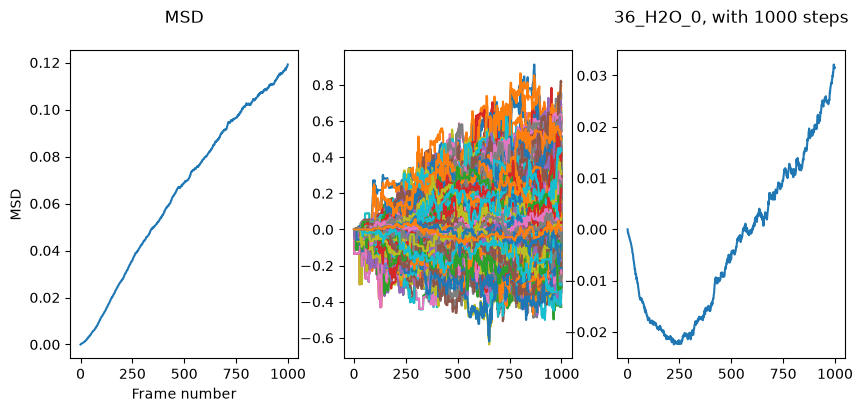

35c43c43ca3c5ae748f6be7b54dc4eb6
average image 0.0019438717067583047
shape of positions (194, 3000, 3)
size of position scaled masses: (3000, 194, 3)
size of final position of masses  (194, 3)


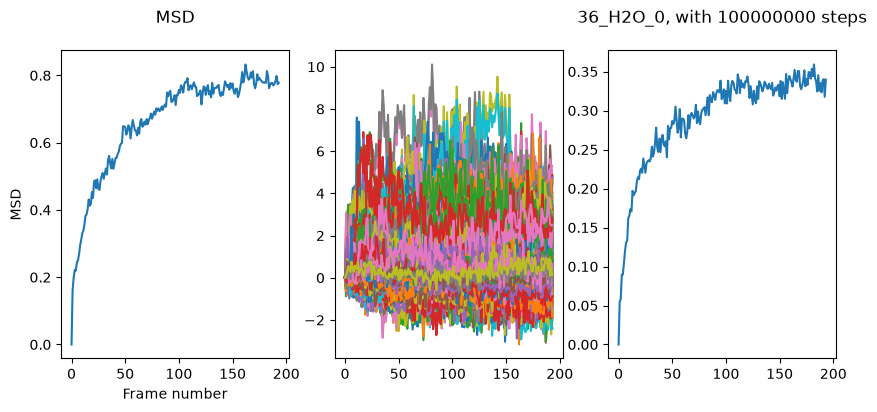

ca4cea06ab5cebe79053617a07ca8094
average image 0.03144109772423025
shape of positions (332, 3000, 3)
size of position scaled masses: (3000, 332, 3)
size of final position of masses  (332, 3)


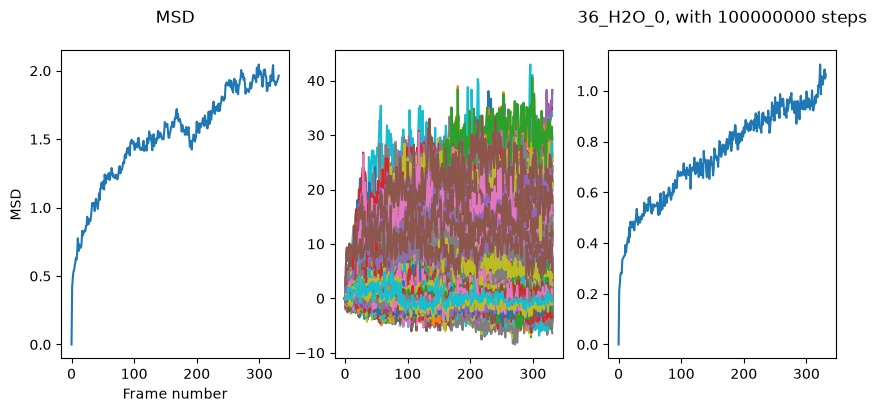

c3dfb88c82e0c945555fcf32eccf3690
average image 0.0030555555555555557
shape of positions (48, 3000, 3)
size of position scaled masses: (3000, 48, 3)
size of final position of masses  (48, 3)


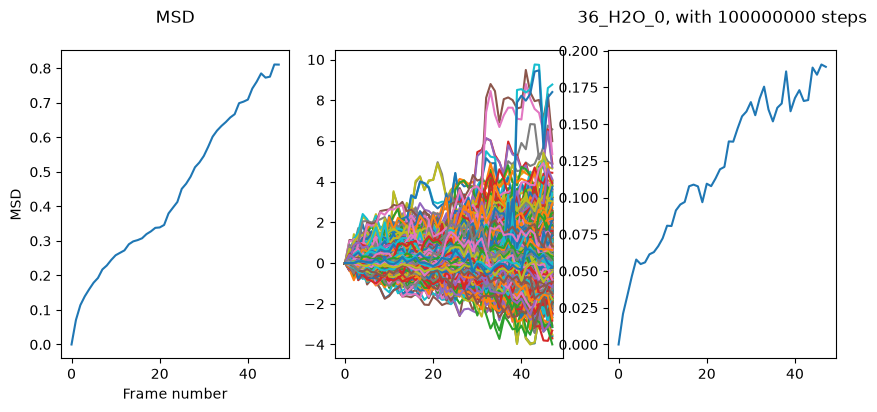

In [ ]:
# relative mean squared displacement between hydrogen and oxygen neighbors 

for job in project.find_jobs({"compression": False, "atoms": ["O", "H"], "crystal_name":"36_H2O_0"}):
    if job.id != "d59772ff5157b86e4e02f4cab5f04d52":
        print(job.id)
        if os.path.isfile(job.fn("trajectory.gsd")):
            data = gsd.hoomd.open(job.fn("trajectory.gsd"), 'r')
            image_retrieval(job.fn("trajectory.gsd"), job.fn("images.npy"))
        else: 
            data = gsd.hoomd.open(job.fn("trajectory_temp.gsd"), 'r')
            print(data)
            if data == None: 
                print("no data")    
                break
            image_retrieval(job.fn("trajectory_temp.gsd"), job.fn("images.npy"))
            

        plot_points = 100
        oxygen_neighbors = np.zeros(plot_points)

        num_frames = len(data)
        N = data[0].particles.N
        positions = np.zeros((num_frames, N, 3), dtype = float)
        images = np.load(job.fn("images.npy"))
        print("average image", np.average(images))
        for i, snap in enumerate(data): 
            box = freud.box.Box.from_box(snap.configuration.box)
            positions[i] = box.unwrap(snap.particles.position, images[i, :, :])

        # # calculate center of mass, subtract from all trajectories
        # print(f"shape of positions {np.shape(positions)}")
        # com_calc = com(positions, data[0].particles.mass, N)
        # com_array = np.array([com_calc]*N)
        
        #com_transpose = np.array(np.transpose(com_array, axes = [1, 0, 2]))
        
        #ositions_nocom = positions - com_transpose 

        points = data[0].particles.position

        msd_obj = freud.msd.MSD(box, mode = "direct")
        msd_computed = msd_obj.compute(positions)

        #msd_computed_nocom = msd_obj.compute(positions_nocom)

        # take per particle msd of computed msd 
        pmsd = msd_computed.particle_msd

        aq = freud.locality.AABBQuery(box, points)

        query_ids = np.where(data[0].particles.typeid == 1)
        query_points = data[0].particles.position[query_ids]

        query_result = aq.query(query_points, dict(num_neighbors=4, exclude_ii=True))

        nlist = query_result.toNeighborList() 

        HO_pair_list = np.array([[i, j] for i, j in nlist if [snap.particles.typeid[i], snap.particles.typeid[j]] == [1, 0]])

        pair_relative_msd = pmsd[:, HO_pair_list[:, 0]] - pmsd[:, HO_pair_list[:, 1]]

        ## plot for each 
        fig, axs = plt.subplots(1, 3, sharex='col', figsize=(10, 4))
        plt.title(f"{job.sp.crystal_name}, with {job.sp.runtime} steps")

        msd_computed.plot(ax=axs[0]) 

        axs[1].plot(pair_relative_msd)
        
        axs[2].plot(np.average(pair_relative_msd, axis = 1))
        #plt.title(f"average rmsd, {job.sp.crystal_name}, with {job.sp.runtime} steps")
        plt.show()

        # ### plot for each 
        # fig, axs = plt.subplots(1, 2, sharex='col', figsize=(10, 4))
        # plt.title(f"{job.sp.crystal_name}, with {job.sp.runtime} steps")

        # msd_computed.plot(ax=axs[0]) 
        # msd_computed_nocom.plot(ax=axs[1])

        # plt.show()
        

        